# Base Model
## Classes:

- Bigparent 
    - Parent (Population)
        - Pair (Conditional)
        - System (Population)
            - Pair_comp (Conditonal)?
            - Component (Population)

## Attributes:
- Role: \{Admin, Superuser, User, Guest\} --> Parent
- Size: \{S, M, L, XL\} --> System

## Assignment Logic:

$C_i \in Sys_j$ for some $i$, for all $j$

$Sys_j \in Par_k$ for some $k$, for all $k$

$ \forall \ k \ \exists \ 1 \ BigP: {Par_k \mapsto BigP_l}$ 



In [ ]:
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx
from collections import defaultdict



class Component:
    def __init__(self, name, maps):
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.name = name
        self.systems = comp_sys_map[name]
        self.parents = sorted(list(set().union(*[sys_parent_map[sys] for sys in self.systems])))
        self.bigparents = sorted(list(set([parent_bigparent_map[parent] for parent in self.parents])))
        self.sizes = sorted(list(set([sys_size_map[sys] for sys in self.systems])))
        self.roles = sorted(list(set().union(*[parent_role_map[parent] for parent in self.parents])))
        self.data = {}
        self.parameters = {}
        self.true_paramters = {
            "mtbf_lambda": np.random.uniform(100, 10000),
            "mttr_lambda": np.random.uniform(80, 8000),
            "spare_rate": np.random.uniform(0.1, 1.25),
            "unit_price": np.random.uniform(100, 10000),
            "important": np.random.choice([True, False], p=[0.8, 0.2])
        }

class System:
    def __init__(self, name, maps):
        self.name = name
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.components = [comp for comp, sys_list in comp_sys_map.items() if name in sys_list]
        self.parents = sorted(list(set(sys_parent_map[name])))
        self.bigparents = sorted(list(set([parent_bigparent_map[parent] for parent in self.parents])))
        self.size = sys_size_map[name]
        self.roles = sorted(list(set().union(*[parent_role_map[parent] for parent in self.parents])))
        self.data = {}
        self.parameters = {}
        self.true_parameters = {
            "say_hio": (np.random.randint(70, 100),np.random.randint(1, 30)),
            "speed": np.random.uniform(1, 8),
            "efficiency": np.random.uniform(0.5, 1.0)
        }

    def create_maintenance_record(self):
        log = []
        while time < 100000:
            part = np.random.choice(self.components)
            time_to_failure = np.random.exponential(part.true_paramters["mtbf_lambda"])
            time_to_repair = np.random.exponential(part.true_paramters["mttr_lambda"])
            log.append([time, time+time_to_failure, time+time_to_failure+time_to_repair, part])
            time += time_to_failure + time_to_repair
    
    def parse_traffic(self, tr_df):
        sub_df = tr_df[tr_df["system"] == self.name]
        if sub_df.empty:
            return
        self.data["traffic"] = sub_df
        param1 = self.data["traffic"]["arrived"].value_counts().iloc[0] + 1
        param2 = self.data["traffic"]["arrived"].count() - param1 + 1
        self.parameters["traffic_beta_params"] = (param1, param2)
        param_set = stats.weibull_min.fit(self.data["traffic"]["speed"], floc=0)
        self.parameters["traffic_weibull_params"] = param_set

    def parse_hi(self, hi_df):
        sub_df = hi_df[hi_df['system'] == self.name]
        if sub_df.emtpy:
            return 
        self.data["hi"] = sub_df
        param1 = self.data["hi"]["hello"].sum() + 1
        param2 = self.data["hi"]["hello"].count() - param1 + 1
        self.parameters["hi"] = (param1, param2)



class Parent: 
    def __init__(self, name, maps):
        self.name = name
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.components = [comp for comp, sys_list in comp_sys_map.items() if any(sys in sys_list for sys in sys_parent_map if name in sys_parent_map[sys])]
        self.systems = [sys for sys, parent_list in sys_parent_map.items() if name in parent_list]
        self.sizes = sorted(list(set([sys_size_map[sys] for sys in self.systems])))
        self.bigparent = parent_bigparent_map[name]
        self.roles = sorted(list(set(parent_role_map[name])))
        self.data = {}
        self.parameters = {}
        self.true_parameters = None
    
    def parse_traffic(self, tr_df):
        sub_df = tr_df[tr_df["source"] == self.name]
        if sub_df.empty:
            return 
        self.data["traffic"] = sub_df
        param1 = self.data["traffic"]["arrived"].value_counts().iloc[0]
        param2 = self.data["traffic"]["arrived"].count() - param1
        self.parameters["traffic_beta_params"] = (param1, param2)
        param_set = stats.weibull_min.fit(self.data["traffic"]["speed"], floc=0)
        self.parameters["traffic_weibull_params"] = param_set

    def parse_hi(self, hi_df):
        sub_df = hi_df[hi_df["parent"] == self.name]
        if sub_df.empty:
            return 
        self.data["hi"] = sub_df
        param1 = self.data["hi"]["hello"].sum() + 1
        param2 = self.data["hi"]["hello"].count() - param1 + 1
        self.parameters["hi"] = (param1, param2)


class BigParent:
    def __init__(self, name, maps):
        self.name = name
        comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.parents = [parent for parent, bigparent in parent_bigparent_map.items() if bigparent == name]
        self.systems = sorted(list(set([sys for sys, parent_list in sys_parent_map.items() if any(parent in parent_list for parent in self.parents)])))
        self.components = sorted(list(set([comp for comp, sys_list in comp_sys_map.items() if any(sys in sys_list for sys in self.systems)])))
        self.sizes = sorted(list(set([sys_size_map[sys] for sys in self.systems])))
        self.roles = list(set().union(*[parent_role_map[parent] for parent in self.parents]))
    
class Pair:
    def __init__(self, parent, system, maps):
        self.parent = parent
        self.system = system
        comp_sys_map, _, parent_bigparent_map, sys_size_map, parent_role_map = maps
        self.components = [comp for comp, sys_list in comp_sys_map.items() if system in sys_list]
        self.size = sys_size_map[system]
        self.bigparent = parent_bigparent_map[parent]
        self.roles = sorted(list(set(parent_role_map[parent])))
        self.data = {}
    
    def parse_traffic(self, tr_df):
        pass

    def parse_hi(self, tr_df):
        pass

        
        

def set_class_objects():
    comp_list = [f"comp_{i}" for i in range(1, 20)]
    sys_list = [f"sys_{i}" for i in range(1, 15)]
    parent_list = [f"par_{i}" for i in range(1, 10)]
    bigparent_list = [f"bigpar_{i}" for i in range(1, 5)]
    size_list = ["S", "M", "L", "XL"]
    roles = ["Admin", "User", "Guest", "Superuser"]

    np.random.seed(123)
    # quant_comp = {comp: np.random.randint(1, 4) for comp in comp_list}
    # quant_sys = {sys: np.random.randint(1, 100) for sys in sys_list}
    # quant_parent = {parent: np.random.randint(1, 100) for parent in parent_list}

    comp_sys_map = {str(comp): np.random.choice(sys_list,size=np.random.randint(1, 6)).astype(str).tolist()for comp in comp_list}
    sys_parent_map = {str(sys): np.random.choice(parent_list,size=np.random.randint(1, 8)).astype(str).tolist()for sys in sys_list}
    parent_bigparent_map = {str(parent): str(np.random.choice(bigparent_list))for parent in parent_list}
    sys_size_map = {str(sys): str(np.random.choice(size_list))for sys in sys_list}
    parent_role_map = {str(parent): np.random.choice(roles,size=np.random.randint(1, 5)).astype(str).tolist()for parent in parent_list}
    maps = (comp_sys_map,sys_parent_map,parent_bigparent_map,sys_size_map,parent_role_map)

    comps = {comp: Component(comp, maps) for comp in comp_list}
    syss = {sys: System(sys, maps) for sys in sys_list}
    parents = {parent: Parent(parent, maps) for parent in parent_list}
    par_sys = {(par, sys): Pair(par, sys) for par, lst in sys_parent_map.items() for sys in lst}
    bigparents = {bigparent: BigParent(bigparent, maps) for bigparent in bigparent_list}
    

    return comps, syss, parents, par_sys, bigparents, comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map







In [136]:

Comps, Sys, Parents, BigParents, comp_sys_map, sys_parent_map, parent_bigparent_map, sys_size_map, parent_role_map = set_class_objects()


In [137]:
def create_edges(Parents, G):
    # Based on the Parent Class
    for parent_i_name in Parents.keys():
        parent_i = Parents[parent_i_name]
        
        # Iterate through each system in parent_i
        for system_name in parent_i.systems:
            system = Sys[system_name]
            
            # Find all parents that have this system
            parents_with_system = sys_parent_map[system_name]
            
            # Check each other parent
            for parent_j_name in parents_with_system:
                if parent_j_name == parent_i_name:
                    continue  # Skip self-loops
                
                parent_j = Parents[parent_j_name]
                
                # Check if they have the same role (at least one role in common)
                common_roles = set(parent_i.roles) & set(parent_j.roles)
                
                if common_roles:
                    # Create edge attributes with system.size and all system.parameters
                    edge_attrs = {
                        "system_name": system_name,
                        "parent_i": parent_i_name,
                        "parent_j": parent_j_name,
                        "system_size": system.size,
                        **system.true_parameters 
                    }
                    
                    # Add edge (using system_name as key for MultiDiGraph to allow multiple edges)
                    G.add_edge(parent_i_name, parent_j_name, key=system_name, **edge_attrs)

    print(f"Added {G.number_of_edges()} edges to the graph")
    print(f"\nExample edge attributes:")
    if G.number_of_edges() > 0:
        first_edge = list(G.edges(keys=True, data=True))[0]
        print(f"Edge {first_edge[0]} -> {first_edge[1]} (system: {first_edge[2]})")
        print(f"Attributes: {first_edge[3]}")
    return G


In [148]:
sys_parent_map
[(k, v) for k, lst in sys_parent_map.items() for v in lst]


[('sys_1', 'par_7'),
 ('sys_2', 'par_9'),
 ('sys_2', 'par_2'),
 ('sys_2', 'par_1'),
 ('sys_2', 'par_4'),
 ('sys_2', 'par_2'),
 ('sys_2', 'par_4'),
 ('sys_2', 'par_5'),
 ('sys_3', 'par_8'),
 ('sys_3', 'par_7'),
 ('sys_3', 'par_2'),
 ('sys_3', 'par_5'),
 ('sys_3', 'par_4'),
 ('sys_3', 'par_4'),
 ('sys_3', 'par_8'),
 ('sys_4', 'par_9'),
 ('sys_4', 'par_7'),
 ('sys_4', 'par_5'),
 ('sys_4', 'par_5'),
 ('sys_4', 'par_8'),
 ('sys_4', 'par_1'),
 ('sys_4', 'par_1'),
 ('sys_5', 'par_9'),
 ('sys_5', 'par_9'),
 ('sys_6', 'par_9'),
 ('sys_6', 'par_7'),
 ('sys_6', 'par_2'),
 ('sys_6', 'par_7'),
 ('sys_6', 'par_9'),
 ('sys_7', 'par_2'),
 ('sys_7', 'par_8'),
 ('sys_7', 'par_2'),
 ('sys_8', 'par_9'),
 ('sys_8', 'par_8'),
 ('sys_9', 'par_4'),
 ('sys_9', 'par_2'),
 ('sys_10', 'par_8'),
 ('sys_11', 'par_2'),
 ('sys_11', 'par_3'),
 ('sys_11', 'par_6'),
 ('sys_11', 'par_3'),
 ('sys_11', 'par_3'),
 ('sys_11', 'par_4'),
 ('sys_12', 'par_7'),
 ('sys_12', 'par_8'),
 ('sys_12', 'par_2'),
 ('sys_13', 'par_4'),
 (

Added 114 edges to the graph

Example edge attributes:
Edge par_1 -> par_9 (system: sys_2)
Attributes: {'system_name': 'sys_2', 'parent_i': 'par_1', 'parent_j': 'par_9', 'system_size': 'M', 'say_hio': (86, 27), 'speed': 2.6273584992296506, 'efficiency': 0.6503050677516024}

Example node attributes:
{'roles': ['Guest', 'Superuser', 'User'], 'bigparent': 'bigpar_4', 'systems': ['sys_2', 'sys_4', 'sys_14']}


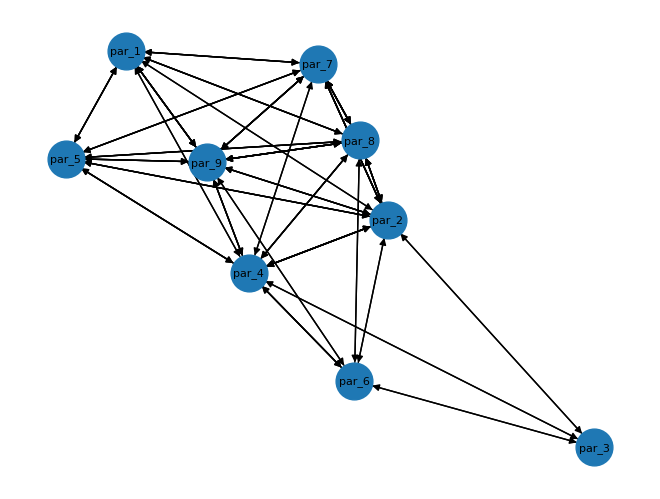

In [138]:
G = nx.MultiDiGraph()
G.add_nodes_from(Parents.keys())
for parent_name, parent_obj in Parents.items():
    G.nodes[parent_name]['roles'] = parent_obj.roles
    G.nodes[parent_name]['bigparent'] = parent_obj.bigparent
    G.nodes[parent_name]['systems'] = parent_obj.systems

G = create_edges(Parents, G)
print(f"\nExample node attributes:\n{list(G.nodes(data=True))[0][1]}")
nx.draw(G, with_labels=True, node_size=700, font_size=8)

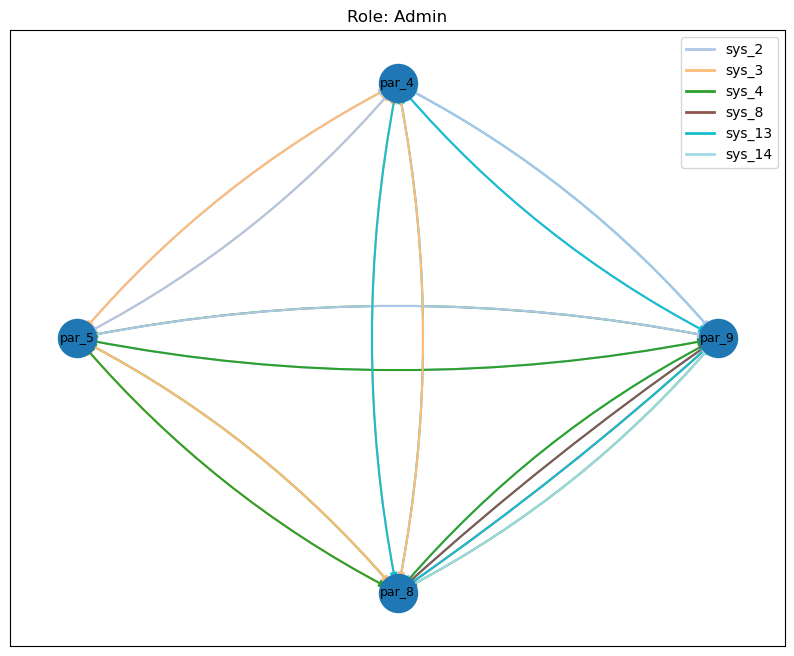

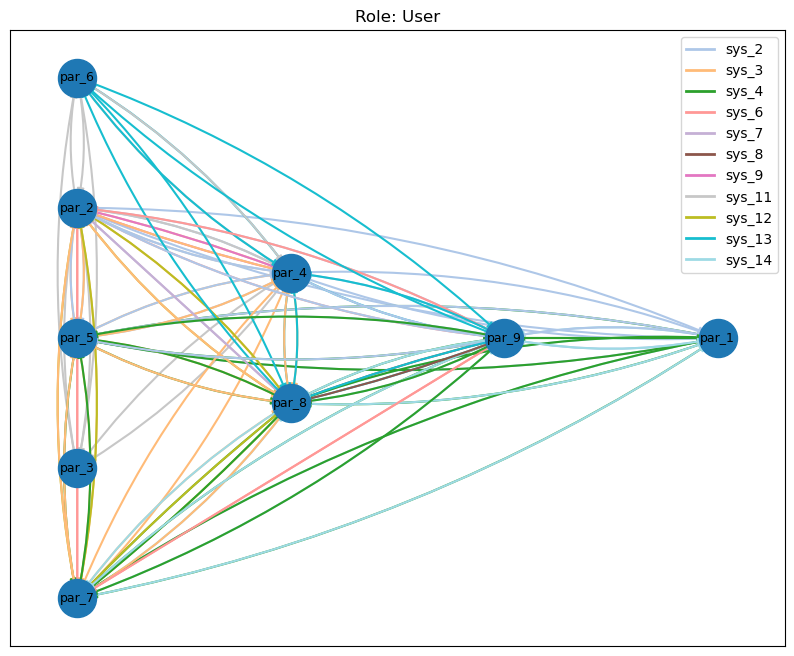

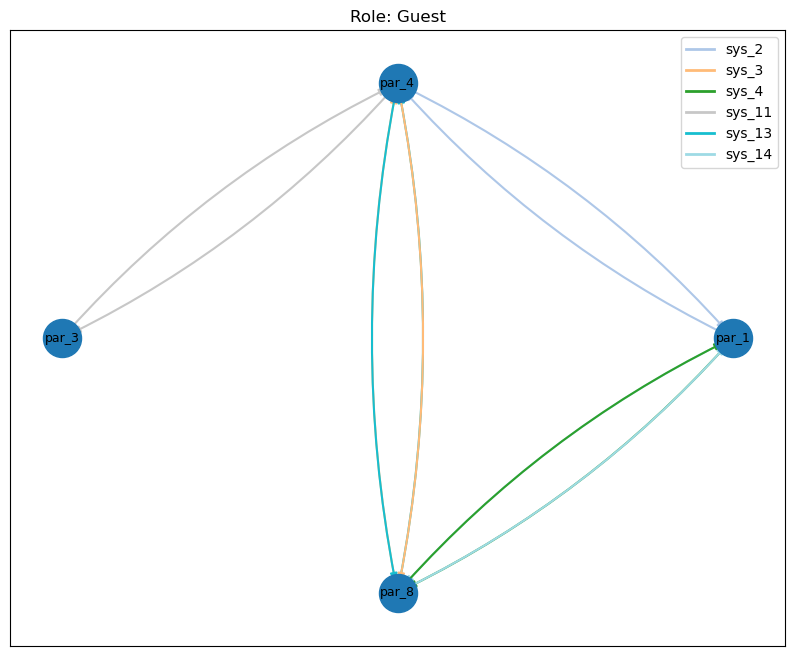

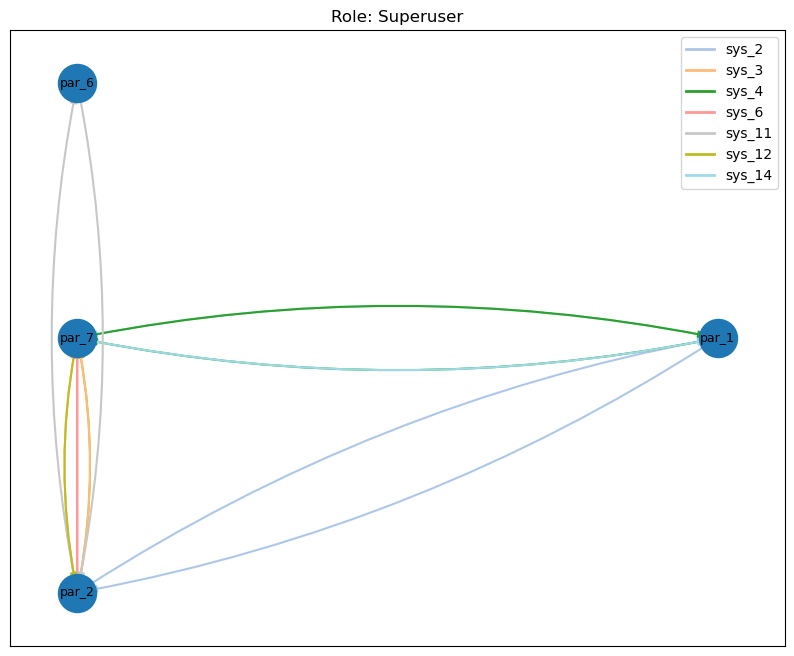

In [139]:
from matplotlib.lines import Line2D
from collections import defaultdict

roles = ["Admin", "User", "Guest", "Superuser"]
role_graphs = {role: G.subgraph([n for n, data in G.nodes(data=True) if role in data.get("roles", [])]) for role in roles}
cmap = plt.get_cmap("tab20", len(Sys.keys()))
system_cmap = {name: cmap(i) for i, name in enumerate(Sys.keys())}

edge_groups = defaultdict(list)


for k, G_sub in role_graphs.items():

    plt.figure(figsize=(10,8))
    plt.title(f"Role: {k}")
    pos = nx.multipartite_layout(G_sub, subset_key='bigparent')
    nx.draw_networkx_nodes(G_sub, pos, node_size=750)
    nx.draw_networkx_labels(G_sub,pos,labels={n: n for n in G_sub.nodes()},font_size=9)

    edge_groups = defaultdict(list)
    for u, v, key, data in G_sub.edges(keys=True, data=True):
        edge_groups[(u, v)].append((key, data))
    for (u, v), edges in edge_groups.items():
        rads = np.linspace(-0.1, 0.1, len(edges))
        for rad, (key, data) in zip(rads, edges):
            nx.draw_networkx_edges(G_sub,pos,edgelist=[(u, v)],edge_color=[system_cmap[data["system_name"]]],width=1.5,connectionstyle=f"arc3,rad={rad}")

    systems_in_subgraph = {d["system_name"]for _, _, _, d in G_sub.edges(keys=True, data=True)}
    handles = [Line2D([0], [0], color=color, lw=2, label=name)for name, color in system_cmap.items()if name in systems_in_subgraph]
    plt.legend(handles=handles, bbox_to_anchor=(1,1))
    plt.show()

## Synthetic Data:
### Create Data:

In [ ]:
def create_traffic(G):
    np.random.seed(123)
    traffic_data = []
    for u, v, key, data in G.edges(keys=True, data=True):
        for n in range(20):
            traffic_data.append({
                "source": u,
                "target": v,
                "system": data["system_name"],
                "size": data["system_size"],
                "speed": np.random.exponential(scale=data["speed"]),
                "arrived": np.random.choice([True, False], p=[data["efficiency"], 1-data["efficiency"]]),
            })
    return pd.DataFrame(traffic_data)

def create_sys_parent_hello(Sys):
    np.random.seed(123)
    hello_data = []
    for sys_obj in Sys.values():
        for parent in sys_obj.parents:
            for i in range(20):
                    hello_data.append({
                        "system": sys_obj.name,
                        "parent": parent,
                        "hello": np.random.beta(*sys_obj.true_parameters["say_hio"])    
                    })
    return pd.DataFrame(hello_data)

tr_df = create_traffic(G)
print(tr_df.head())

hi_df = create_sys_parent_hello(Sys)
print(hi_df.head())

  source target system size      speed  arrived
0  par_1  par_9  sys_2    M   3.132526     True
1  par_1  par_9  sys_2    M   0.675978     True
2  par_1  par_9  sys_2    M   3.339559     True
3  par_1  par_9  sys_2    M  10.380646    False
4  par_1  par_9  sys_2    M   1.722812     True
  system parent     hello
0  sys_1  par_7  0.746604
1  sys_1  par_7  0.733437
2  sys_1  par_7  0.771905
3  sys_1  par_7  0.791879
4  sys_1  par_7  0.806904


### Parse Traffic DF:

In [ ]:
# Parent Params: Population of Parents (source)
for name, par in Parents.items():
    par.parse_traffic(tr_df)

# Sys Params: Population of Systems
for name, sys in Sys.items():
    sys.parse_traffic(tr_df)
    
# Assign traffic data to the graph
for u, v, key, data in G.edges(keys=True, data=True):
    sub_df = tr_df[(tr_df["source"] == u) & (tr_df["target"] == v) & (tr_df["system"] == data["system_name"])]
    if sub_df.empty:
        continue
    edge_traffic = sub_df
    param1 = edge_traffic["arrived"].value_counts().iloc[0]
    param2 = edge_traffic["arrived"].count() - param1
    G.edges[u, v, key]["traffic_beta_params"] = (param1, param2)
    param_set = stats.weibull_min.fit(edge_traffic["speed"], floc=0)
    G.edges[u, v, key]["traffic_weibull_params"] = param_set


### Parse Hi DF

In [ ]:
for name, par in Parents.items():
    sub_df = hi_df[hi_df["parent"] == name]
    par.data["hi"] = sub_df
    if sub_df.empty:
        continue
    param1 = sum(sub_df["hello"]) + 1
    param2 = sub_df["hello"].count() - param1 + 1
    par.parameters["hi"] = (param1, param2)

